# Decoding Video-Elicited Emotions from EEG

6-class emotion classification (anger, sadness, fear, neutral, happy, disgust) from
31-channel EEG, with the test trials drawn from a held-out session unseen at training.


## Executive Summary

Final LOSO accuracy: **0.652 ± 0.135**

Best validation model reached **0.655 ± 0.130**, but I submitted the

**hard-balanced assignment model (Row 9)** because:

- Training data shows every session is perfectly balanced:

  each emotion appears exactly 4 times.

- Test set contains exactly 24 trials from one held-out session.

- This strongly suggests the test session likely follows the same balanced protocol.

- Hard assignment explicitly enforces a 4/4/4/4/4/4 label distribution.

Finding:

The biggest improvement came from **cross-session domain alignment (CORAL)**,

not from using a more complex classifier.

## 1. Check Files

### 1.1 File format

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("raw_files_from_alljoined")

npz = np.load(DATA_DIR / "data.npz", allow_pickle=True)
print("Arrays in data.npz:")
for key in npz.files:
    arr = npz[key]
    print(f"  {key:<8} shape={arr.shape}  dtype={arr.dtype}")

meta = pd.read_csv(DATA_DIR / "trial_info_train.csv")
print(f"\ntrial_info_train.csv: {meta.shape[0]} rows, {meta.shape[1]} cols")
print("Columns:", list(meta.columns))
print(meta.head())

Arrays in data.npz:
  train    shape=(336, 31, 63800)  dtype=float32
  test     shape=(24, 31, 63800)  dtype=float32

trial_info_train.csv: 336 rows, 6 cols
Columns: ['Unnamed: 0', 'session', 'trial_number', 'emotion_label', 'stim_start', 'stim_stop']
   Unnamed: 0  session  trial_number emotion_label    stim_start     stim_stop
0           0        1             0          fear  1.760639e+09  1.760639e+09
1           1        1             1         happy  1.760639e+09  1.760640e+09
2           2        1             2         anger  1.760640e+09  1.760640e+09
3           3        1             3       disgust  1.760640e+09  1.760640e+09
4           4        1             4         happy  1.760640e+09  1.760640e+09


### 1.2 Distribution and trial length

Trials of unequal length are concatenated into a uniform tensor with `inf`-padding,
so true trial length is recovered by locating the first padded sample.

In [2]:
signal_train = npz["train"]
signal_test  = npz["test"]
FS = 200

print("Label distribution:")
print(meta["emotion_label"].value_counts())
print(f"\nSession distribution ({meta['session'].nunique()} sessions):")
print(meta["session"].value_counts().sort_index())
print("\nLabels per session:")
print(pd.crosstab(meta["session"], meta["emotion_label"]))

def true_length(trial):
    is_inf = np.isinf(trial).any(axis=0)
    return int(np.argmax(is_inf)) if is_inf.any() else trial.shape[1]

train_lengths = np.array([true_length(t) for t in signal_train])
test_lengths  = np.array([true_length(t) for t in signal_test])

print(f"\nTrial length (s): "
      f"train [{train_lengths.min()/FS:.1f}, {train_lengths.max()/FS:.1f}], "
      f"test [{test_lengths.min()/FS:.1f}, {test_lengths.max()/FS:.1f}]")

meta["stim_duration"] = meta["stim_stop"] - meta["stim_start"]
print("\nstim_duration vs npz length (s):")
print(pd.DataFrame({
    "stim_duration": meta["stim_duration"].describe(),
    "npz_length":    pd.Series(train_lengths / FS).describe(),
}).round(2))

Label distribution:
emotion_label
fear       56
happy      56
anger      56
disgust    56
neutral    56
sadness    56
Name: count, dtype: int64

Session distribution (14 sessions):
session
1     24
3     24
4     24
5     24
6     24
7     24
8     24
9     24
10    24
11    24
12    24
13    24
14    24
15    24
Name: count, dtype: int64

Labels per session:
emotion_label  anger  disgust  fear  happy  neutral  sadness
session                                                     
1                  4        4     4      4        4        4
3                  4        4     4      4        4        4
4                  4        4     4      4        4        4
5                  4        4     4      4        4        4
6                  4        4     4      4        4        4
7                  4        4     4      4        4        4
8                  4        4     4      4        4        4
9                  4        4     4      4        4        4
10                 4        

## 2. Raw Signal Visualization

We ask whether the raw signal admits a phase-locked, time-domain representation,
or whether we must work in the time–frequency domain.

### 2.1 ERP and Time-Frequency

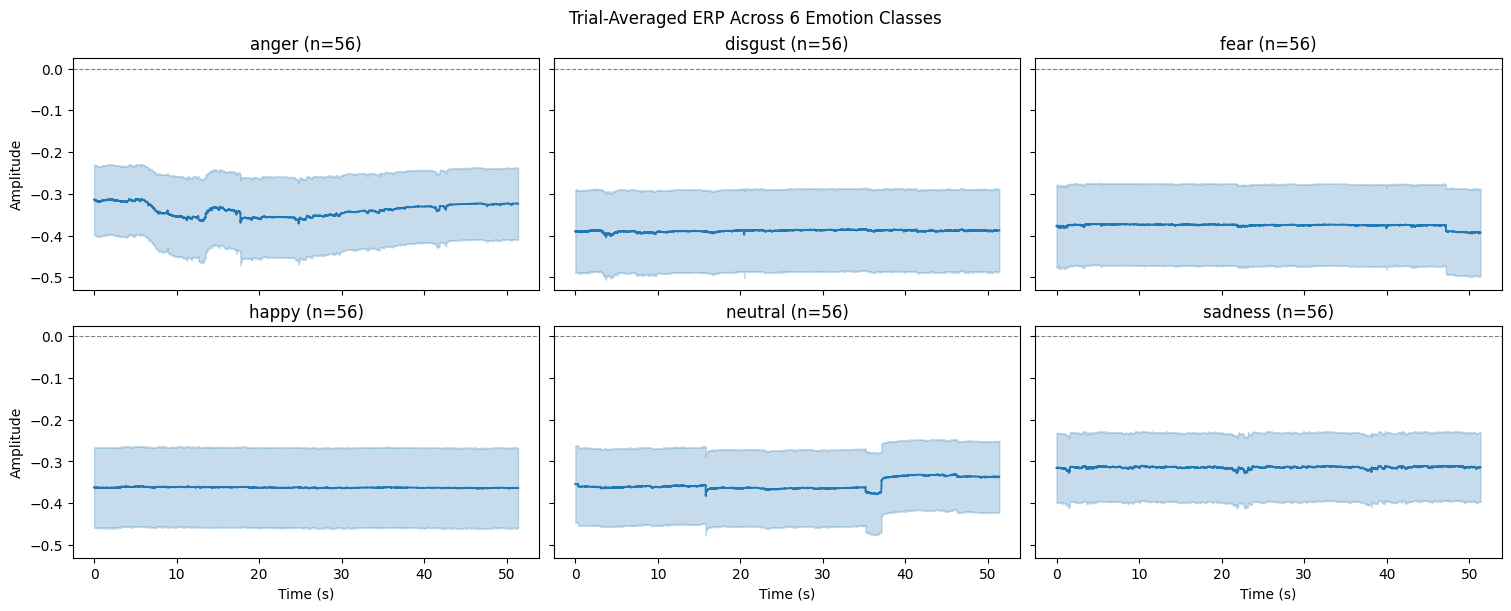

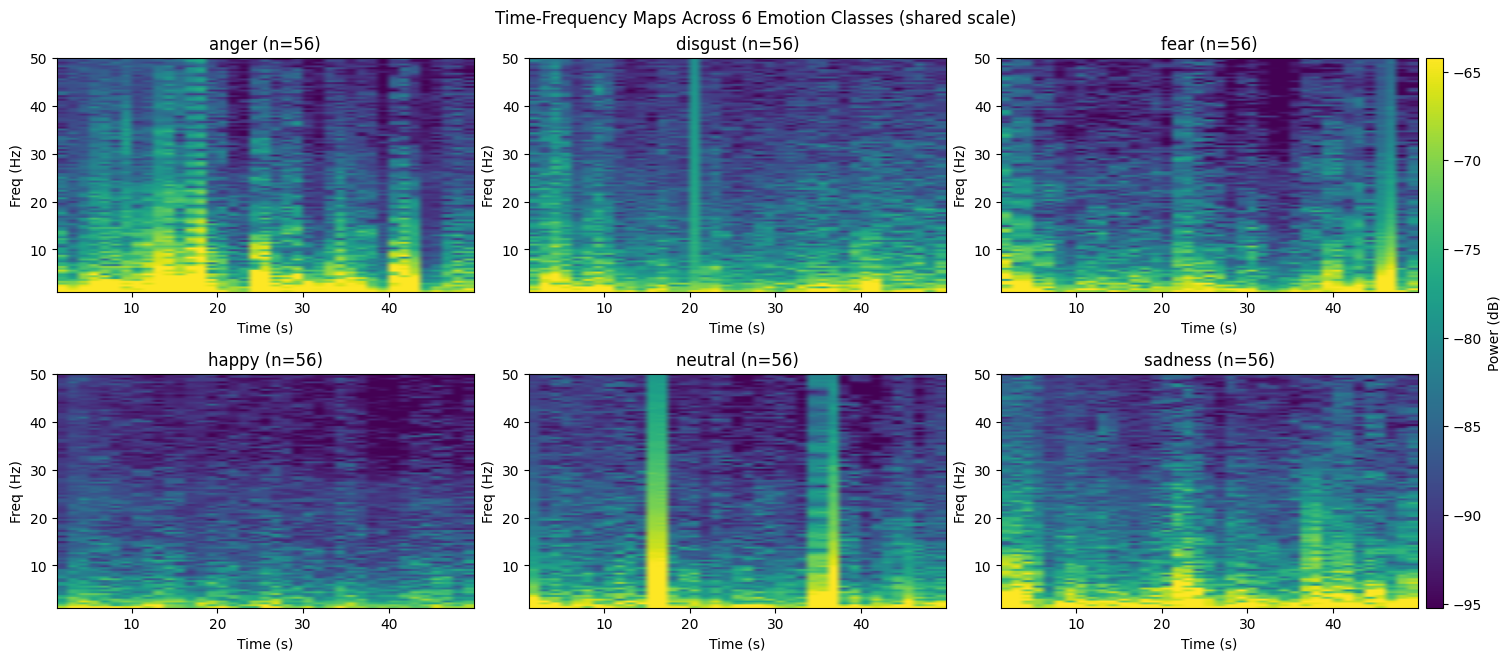

In [5]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy import signal

SAVE_DIR = Path("Signal_Quality_Check/ERP_TF_visualization"); SAVE_DIR.mkdir(exist_ok=True)
CLASS_ORDER  = ["anger", "disgust", "fear", "happy", "neutral", "sadness"]
ERP_CHANNELS = [0, 5, 10, 15, 20, 25, 30]
F_LOW, F_HIGH = 1, 50

X = signal_train
labels = meta["emotion_label"].values
min_len = train_lengths.min()
X_crop = np.stack([x[:, :min_len] for x in X])
time_axis = np.arange(min_len) / FS


# ---------------- ERP ----------------
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, emo in zip(axes.flat, CLASS_ORDER):
    idx = np.where(labels == emo)[0]
    erp = X_crop[idx][:, ERP_CHANNELS, :].mean(axis=1)
    mu, sem = erp.mean(0), erp.std(0) / np.sqrt(len(idx))
    ax.plot(time_axis, mu, color="#1f77b4", lw=1.4)
    ax.fill_between(time_axis, mu - sem, mu + sem, color="#1f77b4", alpha=0.25)
    ax.axhline(0, ls="--", lw=0.8, color="gray")
    ax.set_title(f"{emo} (n={len(idx)})")
for ax in axes[-1]: ax.set_xlabel("Time (s)")
for ax in axes[:, 0]: ax.set_ylabel("Amplitude")
fig.suptitle("Trial-Averaged ERP Across 6 Emotion Classes")
fig.savefig(SAVE_DIR / "ERP_all_classes.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------- Time-Frequency ----------------
def class_tf(class_data, nperseg=512, noverlap=256):
    tfs = []
    for trial in class_data:
        f, t, Sxx = signal.spectrogram(trial, fs=FS, nperseg=nperseg, noverlap=noverlap)
        mask = (f >= F_LOW) & (f <= F_HIGH)
        tfs.append(Sxx[mask])
    return f[mask], t, 10 * np.log10(np.maximum(np.mean(tfs, axis=0), 1e-12))

tf_data = {}
for emo in CLASS_ORDER:
    idx = np.where(labels == emo)[0]
    f_used, t_used, tf_data[emo] = class_tf(X_crop[idx].mean(axis=1))

vmin, vmax = np.percentile(np.stack(list(tf_data.values())), [2, 98])

fig = plt.figure(figsize=(15, 6.5), constrained_layout=True)
gs = GridSpec(2, 4, figure=fig, width_ratios=[1, 1, 1, 0.04])
axes = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(3)]
cax = fig.add_subplot(gs[:, 3])
for ax, emo in zip(axes, CLASS_ORDER):
    im = ax.imshow(tf_data[emo], aspect="auto", origin="lower",
                   extent=[t_used[0], t_used[-1], f_used[0], f_used[-1]],
                   vmin=vmin, vmax=vmax, cmap="viridis")
    n = (labels == emo).sum()
    ax.set_title(f"{emo} (n={n})")
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Freq (Hz)")
fig.colorbar(im, cax=cax, label="Power (dB)")
fig.suptitle("Time-Frequency Maps Across 6 Emotion Classes (shared scale)")
fig.savefig(SAVE_DIR / "TF_all_classes.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation.** 

- ERPs converge to a near-flat trace with overlapping SEM bands and
no class-specific morphology, indicating the affective response is non-phase-locked, so ERP
features are uninformative. 

- In the TF maps, class-discriminative power concentrates
below ~10 Hz, but the band is dominated by 1/f drift; mid-band streaks and
broadband vertical bursts indicate residual EMG and motion artifacts. This motivates
high-pass filtering, edge cropping, and per-window normalization in the pipeline.

### 2.2 Signal Quality Audit

Three-tiered audit before feature extraction: trial level (train vs. test),
channel level, and session level.

In [6]:
import seaborn as sns
from scipy.signal import welch
from scipy.stats import ks_2samp

OUT_DIR = Path("Signal_Quality_Check/raw"); OUT_DIR.mkdir(parents=True, exist_ok=True)
C_TRAIN, C_TEST, C_BAD = "#4C72B0", "#DD8452", "#C44E52"
plt.rcParams.update({
    "font.family": "serif", "font.size": 10,
    "axes.labelsize": 11, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})


def strip_inf(trial):
    return trial[:, ~np.isinf(trial).any(axis=0)]


def robust_z(x):
    med = np.median(x)
    mad = np.median(np.abs(x - med)) + 1e-12
    return 0.6745 * (x - med) / mad


def trial_metrics(trial):
    x = strip_inf(trial)
    ext = np.array([np.mean(np.abs(robust_z(x[c])) > 5) for c in range(x.shape[0])])
    return {"duration_sec": x.shape[1] / FS,
            "mean_std":     x.std(axis=1).mean(),
            "max_ptp":      np.ptp(x, axis=1).max(),
            "extreme_frac": ext.mean()}


def build_df(trials):
    return pd.DataFrame([trial_metrics(t) for t in trials])


def channel_metrics(trials):
    n_ch = trials[0].shape[0]
    rows = []
    for ch in range(n_ch):
        stds, ext, hf = [], [], []
        for trial in trials:
            x = strip_inf(trial)[ch]
            stds.append(x.std())
            ext.append(np.mean(np.abs(robust_z(x)) > 5))
            nperseg = min(int(FS * 2), len(x))
            if nperseg >= 8:
                f, p = welch(x, fs=FS, nperseg=nperseg)
                p_lo = p[(f >= 1)  & (f < 45)].mean()
                p_hi = p[(f >= 45) & (f < 50)].mean()
                hf.append((p_hi + 1e-12) / (p_lo + 1e-12))
        rows.append({"channel": ch, "mean_std": np.mean(stds),
                     "extreme_frac": np.mean(ext), "hf_ratio": np.nanmean(hf)})
    return pd.DataFrame(rows)


# Run audit
q_train = build_df(signal_train); q_train["session"] = meta["session"].values
q_test  = build_df(signal_test)
ch_q    = channel_metrics(signal_train)

# Anomaly score (sum of positive z-scores across 3 stats)
score_cols = ["mean_std", "max_ptp", "extreme_frac"]
for col in score_cols:
    med = q_train[col].median()
    mad = np.median(np.abs(q_train[col] - med)) + 1e-12
    q_train[f"z_{col}"] = 0.6745 * (q_train[col] - med) / mad
q_train["anomaly_score"] = q_train[[f"z_{c}" for c in score_cols]].clip(lower=0).sum(axis=1)

# KS test: train vs test
print("=== Train vs. Test KS test ===")
ks_p = {}
for col in ["duration_sec", "mean_std", "max_ptp", "extreme_frac"]:
    stat, p = ks_2samp(q_train[col], q_test[col])
    ks_p[col] = p
    print(f"  {col:14s}  KS={stat:.3f}  p={p:.4f}")

=== Train vs. Test KS test ===
  duration_sec    KS=0.185  p=0.3902
  mean_std        KS=0.589  p=0.0000
  max_ptp         KS=0.762  p=0.0000
  extreme_frac    KS=0.363  p=0.0039


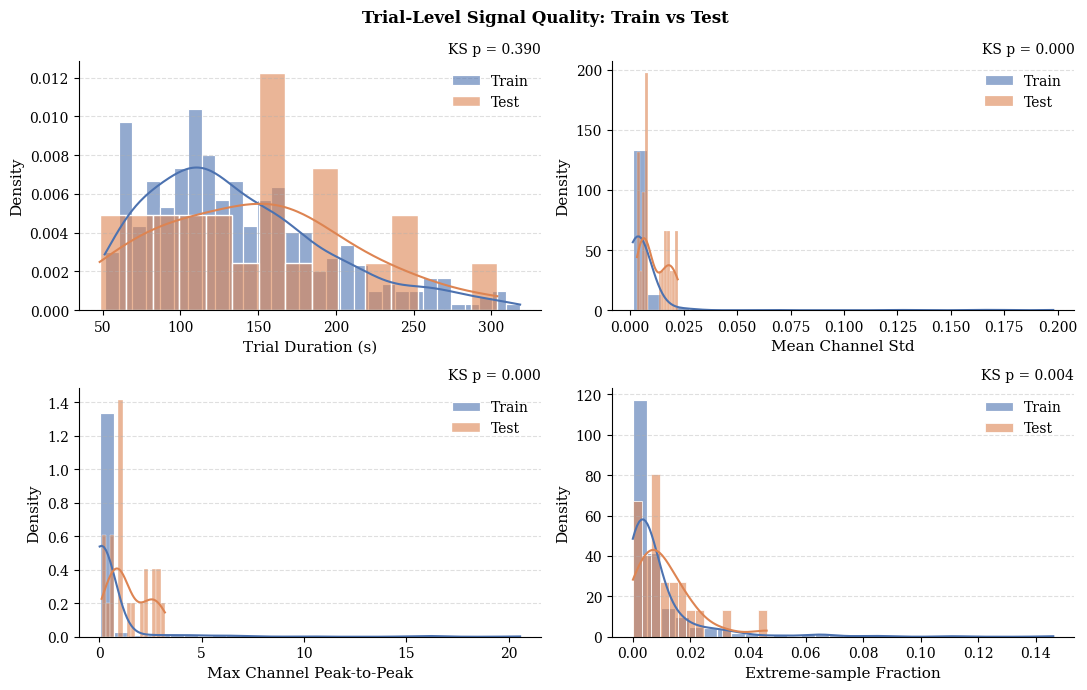

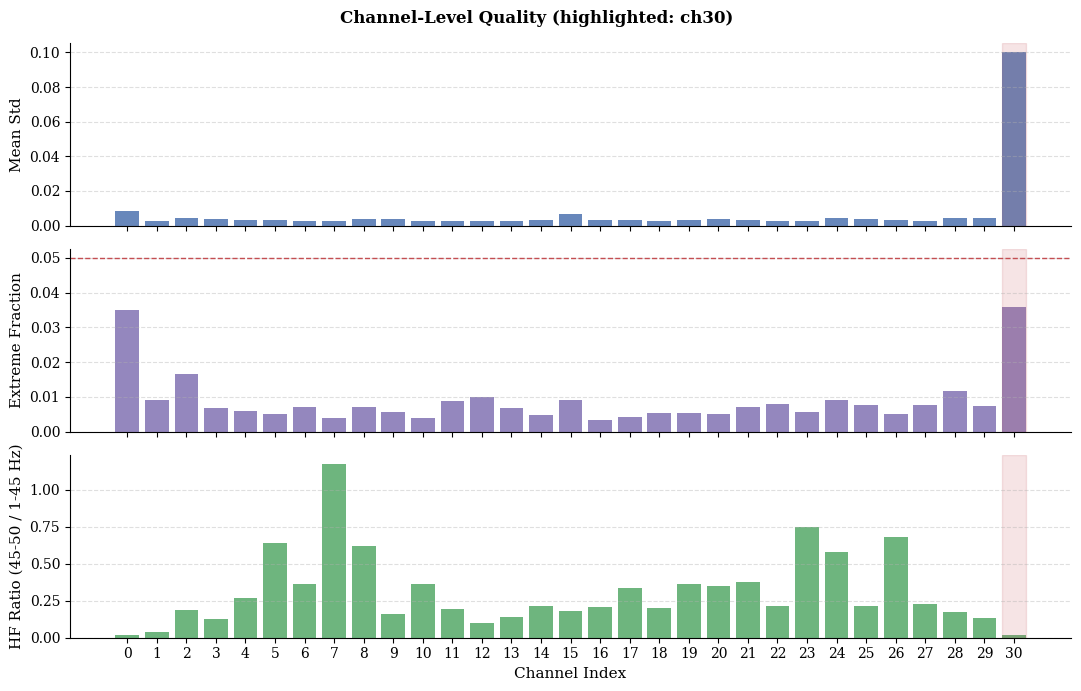

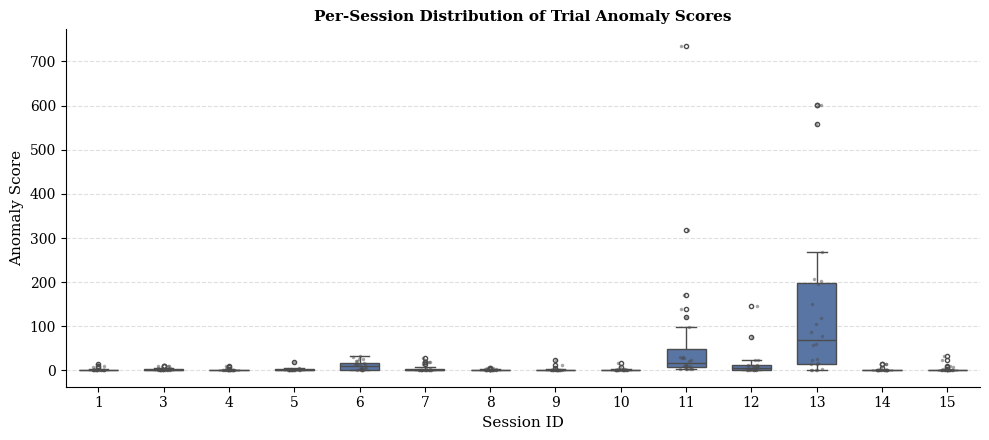


Worst channel by std: ch30
Top-5 worst trials by anomaly:
     session  anomaly_score
221       11     735.994310
278       13     602.515837
271       13     600.399808
269       13     557.283888
227       11     317.218236


In [7]:
# ---------------- Figure 1: Trial-level train vs test ----------------
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [("duration_sec", "Trial Duration (s)"),
          ("mean_std",     "Mean Channel Std"),
          ("max_ptp",      "Max Channel Peak-to-Peak"),
          ("extreme_frac", "Extreme-sample Fraction")]
for ax, (col, lbl) in zip(axes.flat, panels):
    sns.histplot(q_train[col], bins=30, kde=True, color=C_TRAIN, alpha=0.6,
                 label="Train", ax=ax, edgecolor="white", stat="density")
    sns.histplot(q_test[col],  bins=15, kde=True, color=C_TEST,  alpha=0.6,
                 label="Test",  ax=ax, edgecolor="white", stat="density")
    ax.set(xlabel=lbl, ylabel="Density")
    ax.set_title(f"KS p = {ks_p[col]:.3f}", fontsize=10, loc="right")
    ax.grid(axis="y", ls="--", alpha=0.4); ax.legend(frameon=False)
fig.suptitle("Trial-Level Signal Quality: Train vs Test", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig1_trial_quality.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------- Figure 2: Channel-level ----------------
worst_ch = int(ch_q.loc[ch_q["mean_std"].idxmax(), "channel"])
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
configs = [("mean_std",     "Mean Std",                     C_TRAIN),
           ("extreme_frac", "Extreme Fraction",             "#8172B3"),
           ("hf_ratio",     "HF Ratio (45-50 / 1-45 Hz)",   "#55A868")]
for ax, (col, lbl, color) in zip(axes, configs):
    ax.bar(ch_q["channel"], ch_q[col], color=color, alpha=0.85)
    ax.axvspan(worst_ch - 0.4, worst_ch + 0.4, color=C_BAD, alpha=0.15)
    ax.set_ylabel(lbl); ax.grid(axis="y", ls="--", alpha=0.4)
axes[1].axhline(0.05, color=C_BAD, ls="--", lw=1)
axes[-1].set_xlabel("Channel Index"); axes[-1].set_xticks(ch_q["channel"])
fig.suptitle(f"Channel-Level Quality (highlighted: ch{worst_ch})", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig2_channel_quality.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------- Figure 3: Per-session anomaly ----------------
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(x="session", y="anomaly_score", data=q_train,
            color=C_TRAIN, fliersize=3, width=0.6, ax=ax)
sns.stripplot(x="session", y="anomaly_score", data=q_train,
              color=".3", size=2.5, alpha=0.5, ax=ax)
ax.set(xlabel="Session ID", ylabel="Anomaly Score")
ax.set_title("Per-Session Distribution of Trial Anomaly Scores", fontweight="bold")
ax.grid(axis="y", ls="--", alpha=0.4)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig3_session_anomaly.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"\nWorst channel by std: ch{worst_ch}")
print("Top-5 worst trials by anomaly:")
print(q_train.nlargest(5, "anomaly_score")[["session", "anomaly_score"]].to_string())

**Observation.**

- *Trial-level:* duration matches between train and test (p=0.39), but mean channel
  std, peak-to-peak, and extreme-sample fraction differ significantly (p<0.005).
  The held-out session shows an amplitude-scale shift exceeding typical inter-session
  variation, motivating test-time domain alignment.
- *Channel-level:* channel 30 has mean std an order of magnitude above the rest with
  near-zero HF contamination (low-frequency drift, not EMG); we exclude it. Mid-array
  channels (5–8, 23–26) carry elevated HF ratios but are retained.
- *Session-level:* sessions 11 and 13 show elevated anomaly scores; robust per-session
  normalization absorbs most of these outliers.

### 2.3 Cleaning Pipeline + Revisualization

Apply: 

-> drop ch30  

-> crop inf-padding and stimulus duration 

-> edge-crop (3 s front, 1 s back)  

-> linear detrend

-> 0.5 Hz high-pass 

-> per-session robust z-score.

Replot ERP/TF and quality metrics on cleaned data.

In [8]:
from scipy import signal as sps

OUT_DIR = Path("Signal_Quality_Check/cleaned"); OUT_DIR.mkdir(parents=True, exist_ok=True)
DROP_CHANNELS   = [30]
HP_CUTOFF_HZ    = 0.5
EDGE_CROP_FRONT = 3.0
EDGE_CROP_BACK  = 1.0
ERP_CHANNELS_C  = [0, 5, 10, 15, 20, 25]   # post-drop indices

X_train_raw = signal_train
X_test_raw  = signal_test
y_train     = meta["emotion_label"].values
sessions    = meta["session"].values
meta["stim_duration_samples"] = np.round(
    (meta["stim_stop"] - meta["stim_start"]) * FS).astype(int)

sos_hp = sps.butter(4, HP_CUTOFF_HZ, btype="highpass", fs=FS, output="sos")


def non_inf_length(trial):
    pad = np.isinf(trial).any(axis=0)
    return int(np.argmax(pad)) if pad.any() else trial.shape[1]


def clean_trial(trial, usable_len):
    keep = [c for c in range(trial.shape[0]) if c not in DROP_CHANNELS]
    x = trial[keep, :int(usable_len)]
    front, back = int(EDGE_CROP_FRONT * FS), int(EDGE_CROP_BACK * FS)
    if x.shape[1] > front + back + 16:
        x = x[:, front:x.shape[1] - back]
    x = sps.detrend(x, axis=1, type="linear")
    return sps.sosfiltfilt(sos_hp, x, axis=1)


def per_session_robust_z(trials, sess_arr):
    out = [None] * len(trials)
    for s in np.unique(sess_arr):
        idx = np.where(sess_arr == s)[0]
        cat = np.concatenate([trials[i] for i in idx], axis=1)
        med = np.median(cat, axis=1, keepdims=True)
        mad = np.median(np.abs(cat - med), axis=1, keepdims=True)
        mad = np.where(mad < 1e-8, 1.0, mad)
        for i in idx:
            out[i] = 0.6745 * (trials[i] - med) / mad
    return out


print("Cleaning train...")
train_usable = np.minimum(
    np.array([non_inf_length(t) for t in X_train_raw]),
    meta["stim_duration_samples"].to_numpy())
train_clean = [clean_trial(t, L) for t, L in zip(X_train_raw, train_usable)]
train_clean = per_session_robust_z(train_clean, sessions)

print("Cleaning test...")
test_usable = np.array([non_inf_length(t) for t in X_test_raw])
test_clean = [clean_trial(t, L) for t, L in zip(X_test_raw, test_usable)]
test_clean = per_session_robust_z(test_clean, np.zeros(len(test_clean)))

print(f"Train: {len(train_clean)} trials, channels={train_clean[0].shape[0]}, "
      f"length range=({min(t.shape[1] for t in train_clean)}, "
      f"{max(t.shape[1] for t in train_clean)})")

Cleaning train...
Cleaning test...
Train: 336 trials, channels=30, length range=(9473, 62899)


#### Trial Length Mismatch

We found a mismatch between the trial length inferred from the `.npz` signal
(non-inf samples) and the length computed from `stim_stop - stim_start`. In a few
trials the metadata duration was longer than the actual usable EEG signal, so we use:

```python
usable_length = min(non_inf_length, stim_duration_length)
```

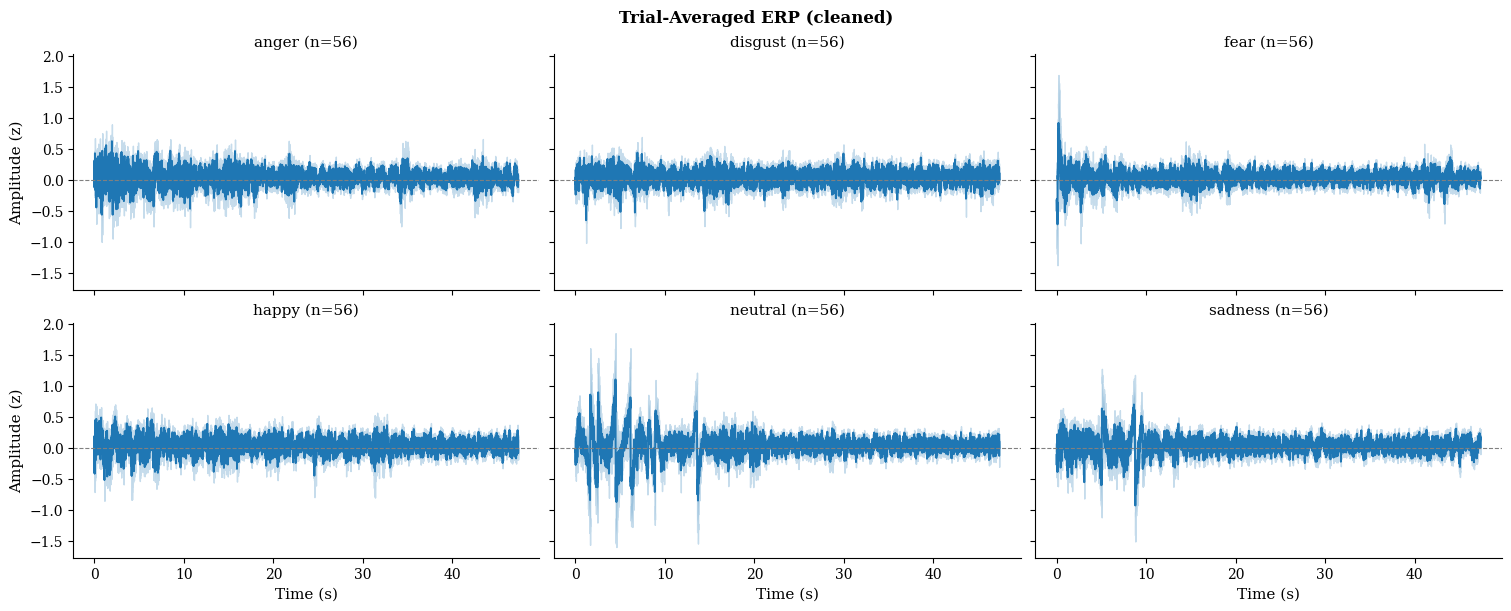

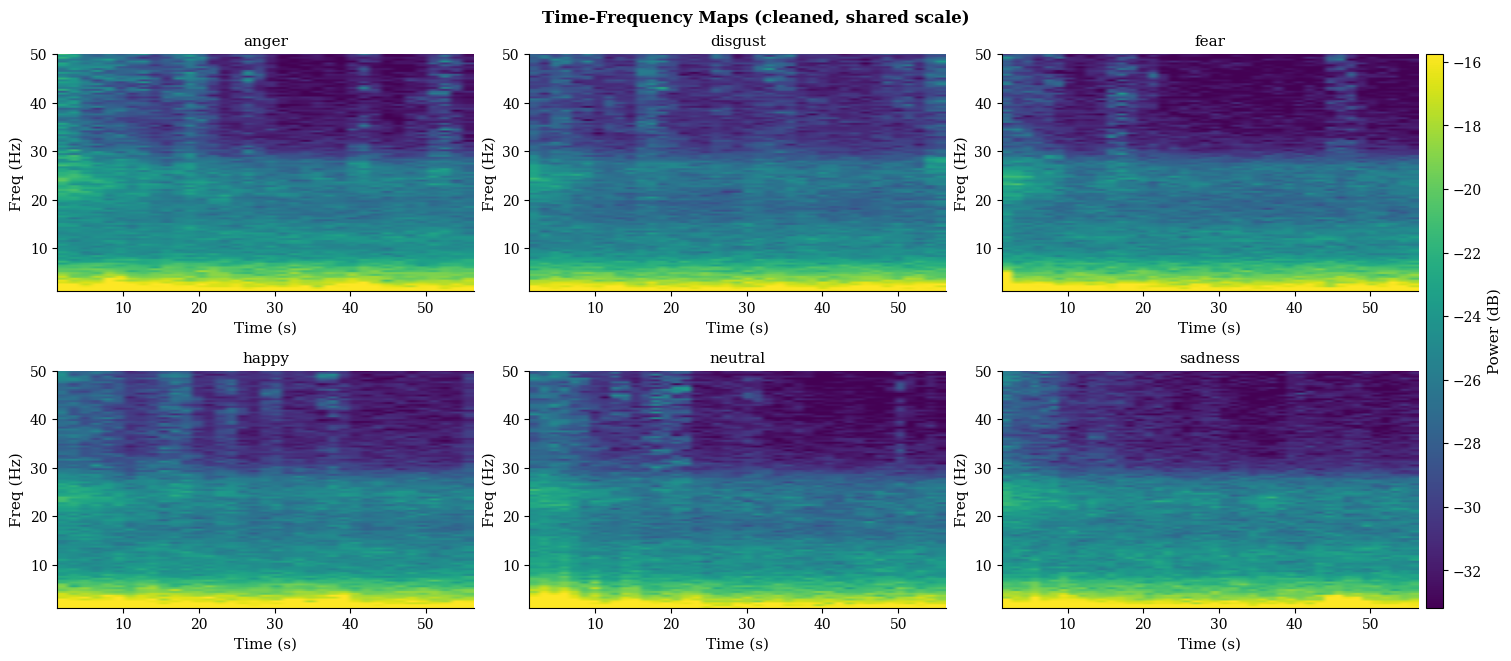

In [9]:
# ---------------- ERP (cleaned) ----------------
def class_avg_erp(trials, labels, channels, n_samples):
    erps = {}
    for emo in CLASS_ORDER:
        idx = np.where(labels == emo)[0]
        stack = np.stack([trials[i][channels, :n_samples] for i in idx])
        per_trial = stack.mean(axis=1)
        erps[emo] = (per_trial.mean(0), per_trial.std(0) / np.sqrt(len(idx)), len(idx))
    return erps


min_len = min(t.shape[1] for t in train_clean)
time_ax = np.arange(min_len) / FS
erps    = class_avg_erp(train_clean, y_train, ERP_CHANNELS_C, min_len)

fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, emo in zip(axes.flat, CLASS_ORDER):
    mu, sem, n = erps[emo]
    ax.plot(time_ax, mu, color="#1f77b4", lw=1.4)
    ax.fill_between(time_ax, mu - sem, mu + sem, color="#1f77b4", alpha=0.25)
    ax.axhline(0, ls="--", lw=0.8, color="gray")
    ax.set_title(f"{emo} (n={n})")
for ax in axes[-1]: ax.set_xlabel("Time (s)")
for ax in axes[:, 0]: ax.set_ylabel("Amplitude (z)")
fig.suptitle("Trial-Averaged ERP (cleaned)", fontweight="bold")
fig.savefig(OUT_DIR / "fig_erp.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------- TF (cleaned) ----------------
def class_tf_clean(trials, labels, nperseg=512, noverlap=256, f_low=1, f_high=50):
    tf, f_used, t_used = {}, None, None
    for emo in CLASS_ORDER:
        idx = np.where(labels == emo)[0]
        L = min(trials[i].shape[1] for i in idx)
        per_class = []
        for i in idx:
            x = trials[i][:, :L].mean(axis=0)
            f, t, S = sps.spectrogram(x, fs=FS, nperseg=min(nperseg, L),
                                      noverlap=min(noverlap, L // 2))
            mask = (f >= f_low) & (f <= f_high)
            per_class.append(S[mask])
        tf[emo] = 10 * np.log10(np.maximum(np.mean(per_class, axis=0), 1e-12))
        f_used, t_used = f[mask], t
    return tf, f_used, t_used


tf_data, f_used, t_used = class_tf_clean(train_clean, y_train)
all_vals = np.concatenate([v.ravel() for v in tf_data.values()])
vmin, vmax = np.percentile(all_vals, [2, 98])

fig = plt.figure(figsize=(15, 6.5), constrained_layout=True)
gs = GridSpec(2, 4, figure=fig, width_ratios=[1, 1, 1, 0.04])
axes = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(3)]
cax = fig.add_subplot(gs[:, 3])
for ax, emo in zip(axes, CLASS_ORDER):
    im = ax.imshow(tf_data[emo], aspect="auto", origin="lower",
                   extent=[t_used[0], t_used[-1], f_used[0], f_used[-1]],
                   vmin=vmin, vmax=vmax, cmap="viridis")
    ax.set_title(emo); ax.set_xlabel("Time (s)"); ax.set_ylabel("Freq (Hz)")
fig.colorbar(im, cax=cax, label="Power (dB)")
fig.suptitle("Time-Frequency Maps (cleaned, shared scale)", fontweight="bold")
fig.savefig(OUT_DIR / "fig_tf.png", dpi=300, bbox_inches="tight")
plt.show()

=== KS test on cleaned data ===
  duration_sec    KS=0.185  p=0.3902
  mean_std        KS=0.527  p=0.0000
  max_ptp         KS=0.714  p=0.0000
  extreme_frac    KS=0.494  p=0.0000


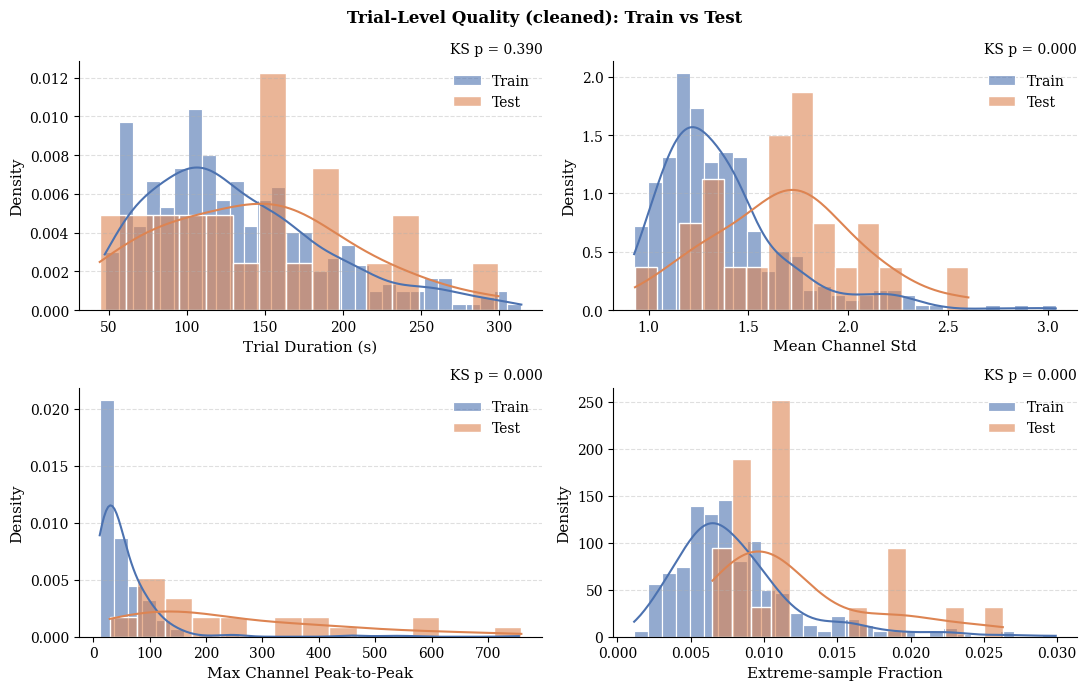

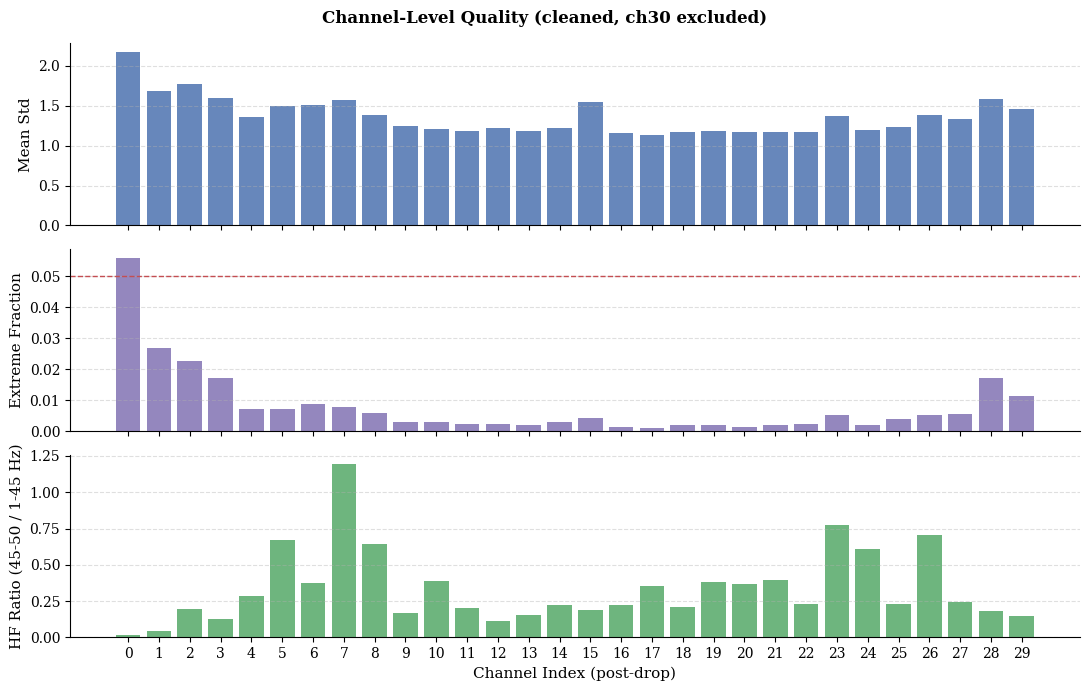

/tmp/ipykernel_1053/427609904.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="session", y="anomaly_score", data=q_train,


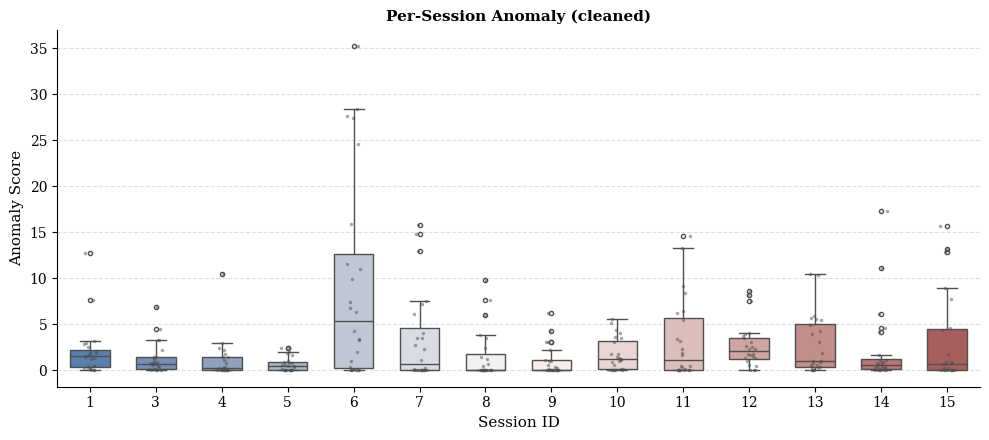

Saved cleaned signals to Signal_Quality_Check/cleaned/cleaned_signals.npz


In [10]:
# ---------------- Quality audit on cleaned data ----------------
def trial_metrics_clean(x):
    ext = np.array([np.mean(np.abs(robust_z(x[c])) > 5) for c in range(x.shape[0])])
    return {"duration_sec": x.shape[1] / FS,
            "mean_std":     x.std(axis=1).mean(),
            "max_ptp":      np.ptp(x, axis=1).max(),
            "extreme_frac": ext.mean()}


def channel_metrics_clean(trials):
    n_ch = trials[0].shape[0]
    rows = []
    for ch in range(n_ch):
        stds, ext, hf = [], [], []
        for x in trials:
            xc = x[ch]
            stds.append(xc.std())
            ext.append(np.mean(np.abs(robust_z(xc)) > 5))
            nperseg = min(int(FS * 2), len(xc))
            if nperseg >= 8:
                f, p = sps.welch(xc, fs=FS, nperseg=nperseg)
                p_lo = p[(f >= 1)  & (f < 45)].mean()
                p_hi = p[(f >= 45) & (f < 50)].mean()
                hf.append((p_hi + 1e-12) / (p_lo + 1e-12))
        rows.append({"channel": ch, "mean_std": np.mean(stds),
                     "extreme_frac": np.mean(ext), "hf_ratio": np.nanmean(hf)})
    return pd.DataFrame(rows)


q_train = pd.DataFrame([{**trial_metrics_clean(x), "session": sessions[i]}
                        for i, x in enumerate(train_clean)])
q_test  = pd.DataFrame([trial_metrics_clean(x) for x in test_clean])
ch_q    = channel_metrics_clean(train_clean)

for col in score_cols:
    med = q_train[col].median()
    mad = np.median(np.abs(q_train[col] - med)) + 1e-12
    q_train[f"z_{col}"] = 0.6745 * (q_train[col] - med) / mad
q_train["anomaly_score"] = q_train[[f"z_{c}" for c in score_cols]].clip(lower=0).sum(axis=1)

print("=== KS test on cleaned data ===")
ks_p = {}
for col in ["duration_sec", "mean_std", "max_ptp", "extreme_frac"]:
    stat, p = ks_2samp(q_train[col], q_test[col])
    ks_p[col] = p
    print(f"  {col:14s}  KS={stat:.3f}  p={p:.4f}")


# ---------------- Trial-level (cleaned) ----------------
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, lbl) in zip(axes.flat, panels):
    sns.histplot(q_train[col], bins=30, kde=True, color=C_TRAIN, alpha=0.6,
                 label="Train", ax=ax, edgecolor="white", stat="density")
    sns.histplot(q_test[col],  bins=15, kde=True, color=C_TEST, alpha=0.6,
                 label="Test",  ax=ax, edgecolor="white", stat="density")
    ax.set(xlabel=lbl, ylabel="Density")
    ax.set_title(f"KS p = {ks_p[col]:.3f}", fontsize=10, loc="right")
    ax.grid(axis="y", ls="--", alpha=0.4); ax.legend(frameon=False)
fig.suptitle("Trial-Level Quality (cleaned): Train vs Test", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_trial_quality.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------- Channel-level (cleaned, ch30 dropped) ----------------
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (col, lbl, color) in zip(axes, configs):
    ax.bar(ch_q["channel"], ch_q[col], color=color, alpha=0.85)
    ax.set_ylabel(lbl); ax.grid(axis="y", ls="--", alpha=0.4)
axes[1].axhline(0.05, color=C_BAD, ls="--", lw=1)
axes[-1].set_xlabel("Channel Index (post-drop)"); axes[-1].set_xticks(ch_q["channel"])
fig.suptitle("Channel-Level Quality (cleaned, ch30 excluded)", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_channel_quality.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------- Session-level (cleaned) ----------------
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(x="session", y="anomaly_score", data=q_train,
            palette="vlag", fliersize=3, width=0.6, ax=ax)
sns.stripplot(x="session", y="anomaly_score", data=q_train,
              color=".3", size=2.5, alpha=0.5, ax=ax)
ax.set(xlabel="Session ID", ylabel="Anomaly Score")
ax.set_title("Per-Session Anomaly (cleaned)", fontweight="bold")
ax.grid(axis="y", ls="--", alpha=0.4)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_session_anomaly.png", dpi=300, bbox_inches="tight")
plt.show()

# Save cleaned signals (variable-length object arrays)
train_arr = np.empty(len(train_clean), dtype=object)
test_arr  = np.empty(len(test_clean), dtype=object)
for i, t in enumerate(train_clean): train_arr[i] = t
for i, t in enumerate(test_clean):  test_arr[i]  = t
np.savez_compressed(OUT_DIR / "cleaned_signals.npz",
                    train=train_arr, test=test_arr,
                    sessions=sessions, labels=y_train)
print(f"Saved cleaned signals to {OUT_DIR / 'cleaned_signals.npz'}")

## 3. LOSO Ablation

Leave-One-Session-Out is the only honest validation protocol: the test session is
unseen at training time, and trials within a session share electrode contact,
impedance, drift, and arousal baseline. We build the pipeline incrementally and
report mean +- std accuracy across the 14 training sessions.

### 3.1 Part 1 - Spectral-only ablation (rows 1-5)

For each row we run LOSO and write per-session results to `ablation_results.csv`,
then retrain on the full training set and emit a submission CSV.

In [11]:
import pickle
from collections import Counter
from scipy import linalg
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.metrics import accuracy_score

# Paths
OUT_DIR    = Path.cwd() / "Results"
SUB_DIR    = OUT_DIR / "submissions"
CSV_PATH   = OUT_DIR / "ablation_results.csv"
CACHE_PATH = OUT_DIR / "_block1_cache.pkl"
SUB_DIR.mkdir(parents=True, exist_ok=True)

# Config
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13),
         "beta":  (13, 30), "gamma_low": (30, 45)}
WIN_SEC, HOP_SEC = 8, 4
TRIM_HEAD_SEC, TRIM_TAIL_SEC, MIN_KEEP_SEC = 4, 2, 8
C_GRID = (0.01, 0.1, 1.0, 10.0)

groups  = meta["session"].values
classes = np.unique(y_train); K = len(classes)
N_TEST  = len(signal_test)

train_non_inf  = np.array([non_inf_length(t) for t in signal_train])
test_non_inf   = np.array([non_inf_length(t) for t in signal_test])
train_full_len = train_non_inf
train_stim_len = np.minimum(train_non_inf, meta["stim_duration_samples"].to_numpy())
test_full_len  = test_non_inf

In [12]:
# ---------------- Feature extractors ----------------
def remove_channels(t, drop):
    if not drop: return t
    keep = [i for i in range(t.shape[0]) if i not in drop]
    return t[keep]


def crop_with_trim(trial, usable_len, trim_head, trim_tail, min_keep_s=MIN_KEEP_SEC):
    L = int(usable_len)
    x = np.nan_to_num(trial[:, :L], nan=0.0, posinf=0.0, neginf=0.0)
    h, t_ = int(trim_head * FS), int(trim_tail * FS)
    if L - h - t_ < int(min_keep_s * FS):
        return x
    return x[:, h:L - t_]


def welch_bp(seg):
    nperseg = min(FS * 2, seg.shape[1])
    f, psd = welch(seg, fs=FS, axis=1, nperseg=nperseg)
    bp = []
    for lo, hi in BANDS.values():
        idx = (f >= lo) & (f < hi)
        bp.append(psd[:, idx].mean(axis=1) if idx.any() else np.zeros(seg.shape[0]))
    return np.log(np.stack(bp, axis=1) + 1e-10)


_trapz = getattr(np, "trapezoid", getattr(np, "trapz", None))


def diff_entropy(seg):
    nperseg = min(FS * 2, seg.shape[1])
    f, psd = welch(seg, fs=FS, axis=1, nperseg=nperseg)
    out = []
    for lo, hi in BANDS.values():
        idx = (f >= lo) & (f < hi)
        power = _trapz(psd[:, idx], f[idx], axis=1) if idx.any() else np.zeros(seg.shape[0])
        out.append(0.5 * np.log(2 * np.pi * np.e * (power + 1e-10)))
    return np.stack(out, axis=1)


def hjorth(seg):
    dx, ddx = np.diff(seg, axis=1), np.diff(np.diff(seg, axis=1), axis=1)
    vx  = np.var(seg, 1) + 1e-12
    vdx = np.var(dx, 1)  + 1e-12
    vddx= np.var(ddx, 1) + 1e-12
    mob = np.sqrt(vdx / vx)
    com = np.sqrt(vddx / vdx) / (mob + 1e-12)
    return np.stack([np.log(vx + 1e-10), mob, com], axis=1)


def features_full_bp(trial, usable_len, drop, trim_head=0, trim_tail=0):
    x = remove_channels(crop_with_trim(trial, usable_len, trim_head, trim_tail), drop)
    return welch_bp(x).reshape(-1)


def features_windowed(trial, usable_len, drop):
    x = remove_channels(crop_with_trim(trial, usable_len, TRIM_HEAD_SEC, TRIM_TAIL_SEC), drop)
    win, hop = WIN_SEC * FS, HOP_SEC * FS
    segs = [x] if x.shape[1] < win else \
           [x[:, s:s + win] for s in range(0, x.shape[1] - win + 1, hop)]
    bp = np.stack([welch_bp(s)     for s in segs])
    de = np.stack([diff_entropy(s) for s in segs])
    hj = np.stack([hjorth(s)       for s in segs])
    def agg(a):
        a2 = a.reshape(a.shape[0], -1)
        return np.concatenate([a2.mean(0), a2.std(0), np.median(a2, 0)])
    return np.concatenate([agg(bp), agg(de), agg(hj)])


def build_X(trials, usable, extractor, drop, **kw):
    return np.array([extractor(t, usable[i], drop, **kw) for i, t in enumerate(trials)])

In [14]:
# ---------------- Domain alignment + classifier helpers ----------------
def robust_zscore_per_session(X, sess):
    out = np.zeros_like(X)
    for s in np.unique(sess):
        m = sess == s
        med = np.median(X[m], 0, keepdims=True)
        mad = np.median(np.abs(X[m] - med), 0, keepdims=True)
        mad = np.where(mad < 1e-8, 1.0, mad)
        out[m] = (X[m] - med) / (1.4826 * mad)
    return out


def coral_align(Xs, Xt, reg=1e-3):
    ms, mt = Xs.mean(0, keepdims=True), Xt.mean(0, keepdims=True)
    Cs = np.cov(Xs - ms, rowvar=False) + reg * np.eye(Xs.shape[1])
    Ct = np.cov(Xt - mt, rowvar=False) + reg * np.eye(Xt.shape[1])
    A  = np.real(linalg.inv(linalg.sqrtm(Cs))) @ np.real(linalg.sqrtm(Ct))
    return np.real((Xs - ms) @ A + mt)


def pick_C(X, y, Cs=C_GRID, n=3, seed=0):
    skf = StratifiedKFold(n, shuffle=True, random_state=seed)
    best_C, best = Cs[0], -1
    for C in Cs:
        accs = []
        for tr, va in skf.split(X, y):
            clf = Pipeline([("sc", StandardScaler()),
                            ("lr", LogisticRegression(max_iter=3000, C=C,
                                                      class_weight="balanced"))])
            clf.fit(X[tr], y[tr])
            accs.append(clf.score(X[va], y[va]))
        if np.mean(accs) > best:
            best, best_C = np.mean(accs), C
    return best_C


def save_submission(y_pred, filename):
    out_path = SUB_DIR / filename
    pd.DataFrame({"label": y_pred}).to_csv(out_path, index=False, header=False)
    return out_path


def run_pipeline(X_train, X_test, name, sub_filename, use_z=False, use_coral=False):
    if use_z:
        X_train = robust_zscore_per_session(X_train, groups)
        X_test  = robust_zscore_per_session(X_test, np.full(len(X_test), -1))

    rows, Cs_used = [], []
    for tr, va in LeaveOneGroupOut().split(X_train, y_train, groups):
        sess_id = int(groups[va][0])
        Xtr, Xva = X_train[tr], X_train[va]
        if use_coral:
            Xtr = coral_align(Xtr, Xva)
        C = pick_C(Xtr, y_train[tr]); Cs_used.append(C)
        clf = Pipeline([("sc", StandardScaler()),
                        ("lr", LogisticRegression(max_iter=3000, C=C,
                                                  class_weight="balanced"))])
        clf.fit(Xtr, y_train[tr])
        rows.append({"pipeline": name, "session": sess_id,
                     "acc": accuracy_score(y_train[va], clf.predict(Xva))})
    df = pd.DataFrame(rows)
    print(f"  LOSO mean={df['acc'].mean():.4f}  std={df['acc'].std():.4f}")

    # Final model on full train
    Xtr_full = X_train
    if use_coral:
        Xtr_full = coral_align(X_train, X_test)
    C_final = Counter(Cs_used).most_common(1)[0][0]
    final = Pipeline([("sc", StandardScaler()),
                      ("lr", LogisticRegression(max_iter=3000, C=C_final,
                                                class_weight="balanced"))])
    final.fit(Xtr_full, y_train)
    y_pred = final.predict(X_test)
    save_submission(y_pred, sub_filename)
    print(f"  Submission: {sub_filename} -> {dict(pd.Series(y_pred).value_counts())}")
    return df

In [15]:
# ---------------- Build feature sets once ----------------
print("Building features...")
X1_tr = build_X(signal_train, train_full_len, features_full_bp, drop=[])
X1_te = build_X(signal_test,  test_full_len,  features_full_bp, drop=[])

X2_tr = build_X(signal_train, train_full_len, features_full_bp, drop=DROP_CHANNELS)
X2_te = build_X(signal_test,  test_full_len,  features_full_bp, drop=DROP_CHANNELS)

X3_tr = build_X(signal_train, train_stim_len, features_full_bp, drop=DROP_CHANNELS,
                trim_head=TRIM_HEAD_SEC, trim_tail=TRIM_TAIL_SEC)
X3_te = build_X(signal_test,  test_full_len,  features_full_bp, drop=DROP_CHANNELS,
                trim_head=TRIM_HEAD_SEC, trim_tail=TRIM_TAIL_SEC)

X5_tr = build_X(signal_train, train_stim_len, features_windowed, drop=DROP_CHANNELS)
X5_te = build_X(signal_test,  test_full_len,  features_windowed, drop=DROP_CHANNELS)


# ---------------- Run rows 1-5 ----------------
all_dfs = []
print("\n[Row 1] Baseline (raw, full BP)")
all_dfs.append(run_pipeline(X1_tr, X1_te,
    "1. Baseline (raw, full BP)", "submission_row1.csv"))

print("\n[Row 2] + Cleaning (drop ch30)")
all_dfs.append(run_pipeline(X2_tr, X2_te,
    "2. + Cleaning (drop ch30)", "submission_row2.csv"))

print("\n[Row 3] + Stim crop + head/tail trim")
all_dfs.append(run_pipeline(X3_tr, X3_te,
    "3. + Stim crop + head/tail trim", "submission_row3.csv"))

print("\n[Row 4] + Per-session z + CORAL")
all_dfs.append(run_pipeline(X3_tr, X3_te,
    "4. + Per-session z + CORAL", "submission_row4.csv",
    use_z=True, use_coral=True))

print("\n[Row 5] + Windowing + DE + Hjorth")
all_dfs.append(run_pipeline(X5_tr, X5_te,
    "5. + Windowing + DE + Hjorth", "submission_row5.csv",
    use_z=True, use_coral=True))


# Save CSV + cache windowed features for blocks 2/3
df_all = pd.concat(all_dfs, ignore_index=True)
df_all.to_csv(CSV_PATH, index=False)
with open(CACHE_PATH, "wb") as f:
    pickle.dump({"X5_tr": X5_tr, "X5_te": X5_te,
                 "train_stim_len": train_stim_len, "test_full_len": test_full_len}, f)

print("\n=== Block 1 summary ===")
print(df_all.groupby("pipeline", sort=False)["acc"].agg(["mean", "std"]).round(4))

Building features...

[Row 1] Baseline (raw, full BP)
  LOSO mean=0.4524  std=0.1316
  Submission: submission_row1.csv -> {'fear': np.int64(12), 'sadness': np.int64(9), 'neutral': np.int64(2), 'disgust': np.int64(1)}

[Row 2] + Cleaning (drop ch30)
  LOSO mean=0.4821  std=0.1273
  Submission: submission_row2.csv -> {'fear': np.int64(12), 'sadness': np.int64(9), 'neutral': np.int64(2), 'anger': np.int64(1)}

[Row 3] + Stim crop + head/tail trim
  LOSO mean=0.5030  std=0.1126
  Submission: submission_row3.csv -> {'sadness': np.int64(21), 'neutral': np.int64(2), 'anger': np.int64(1)}

[Row 4] + Per-session z + CORAL
  LOSO mean=0.5833  std=0.1201
  Submission: submission_row4.csv -> {'disgust': np.int64(6), 'happy': np.int64(5), 'anger': np.int64(4), 'sadness': np.int64(3), 'fear': np.int64(3), 'neutral': np.int64(3)}

[Row 5] + Windowing + DE + Hjorth
  LOSO mean=0.6369  std=0.1114
  Submission: submission_row5.csv -> {'anger': np.int64(6), 'neutral': np.int64(5), 'disgust': np.int64(5),

### 3.2 Part 2: Riemannian ensemble at fixed w=0.9 (rows 6-7)

Add a windowed Riemannian tangent-space classifier and combine with the spectral
head via log-probability averaging:
- Row 6: soft prior balancing (Sinkhorn-style)
- Row 7: hard balanced assignment (Hungarian) — exploits the known uniform test prior


In [18]:
from scipy.optimize import linear_sum_assignment
from pyriemann.estimation import Covariances, Shrinkage
from pyriemann.tangentspace import TangentSpace

LOSO_PROBS_PATH = OUT_DIR / "_loso_probs.pkl"
TEST_PROBS_PATH = OUT_DIR / "_test_probs.pkl"
RIEM_WIN_SEC, RIEM_HOP_SEC = 4, 2
W_FIXED = 0.9


def trial_to_windows(trial, usable_len):
    x = remove_channels(crop_with_trim(trial, usable_len, TRIM_HEAD_SEC, TRIM_TAIL_SEC),
                        DROP_CHANNELS)
    win, hop = RIEM_WIN_SEC * FS, RIEM_HOP_SEC * FS
    if x.shape[1] < win:
        return x[None]
    return np.stack([x[:, s:s + win] for s in range(0, x.shape[1] - win + 1, hop)])


def build_riem_dataset(trials, usable, labels=None):
    wins, tidx, labs = [], [], []
    for i, t in enumerate(trials):
        w = trial_to_windows(t, usable[i])
        wins.append(w); tidx.append(np.full(len(w), i))
        if labels is not None:
            labs.append(np.full(len(w), labels[i]))
    return (np.concatenate(wins), np.concatenate(tidx),
            np.concatenate(labs) if labels is not None else None)


def align_p(clf_classes, p, classes):
    order = [list(clf_classes).index(c) for c in classes]
    return p[:, order]


def soft_balance(log_probs, n_iter=50, tol=1e-6):
    N, k = log_probs.shape
    target = N * np.ones(k) / k
    lp = log_probs - log_probs.max(1, keepdims=True)
    p = np.exp(lp); p = p / p.sum(1, keepdims=True)
    b = np.zeros(k)
    for _ in range(n_iter):
        pb = p * np.exp(b)[None]; pb = pb / pb.sum(1, keepdims=True)
        d = np.log((target + 1e-12) / (pb.sum(0) + 1e-12))
        if np.abs(d).max() < tol: break
        b += d
    pf = p * np.exp(b)[None]; pf = pf / pf.sum(1, keepdims=True)
    return np.log(pf + 1e-12)


def hard_balanced_assignment(log_probs, K_):
    N, _ = log_probs.shape
    if N % K_ != 0:
        return soft_balance(log_probs).argmax(1)
    q = N // K_
    cost = np.empty((N, N))
    for k in range(K_):
        cost[:, k * q:(k + 1) * q] = -log_probs[:, [k]]
    _, col_ind = linear_sum_assignment(cost)
    pred = np.empty(N, dtype=int)
    for r, c in enumerate(col_ind):
        pred[r] = c // q
    return pred

In [17]:
# ---------------- LOSO: collect spec + riem probabilities ----------------
print("Building Riemannian windowed dataset...")
W_train, W_ti, W_lab = build_riem_dataset(signal_train, train_stim_len, y_train)
print(f"  shape: {W_train.shape}")

X5_tr_z = robust_zscore_per_session(X5_tr, groups)

P_spec_l, P_riem_l, Y_l, S_l, Cs_used = [], [], [], [], []
print("\nRunning LOSO...")
for tr, va in LeaveOneGroupOut().split(X5_tr_z, y_train, groups):
    sess_id = int(groups[va][0])
    Xtr_al = coral_align(X5_tr_z[tr], X5_tr_z[va])
    C = pick_C(Xtr_al, y_train[tr]); Cs_used.append(C)
    spec = Pipeline([("sc", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=3000, C=C,
                                               class_weight="balanced"))])
    spec.fit(Xtr_al, y_train[tr])
    p_spec = align_p(spec.classes_, spec.predict_proba(X5_tr_z[va]), classes)

    tr_m, va_m = np.isin(W_ti, tr), np.isin(W_ti, va)
    riem = Pipeline([
        ("cov", Covariances(estimator="oas")),
        ("sh",  Shrinkage(shrinkage=0.1)),
        ("ts",  TangentSpace(metric="riemann")),
        ("sc",  StandardScaler()),
        ("lr",  LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced"))])
    riem.fit(W_train[tr_m], W_lab[tr_m])
    p_riem_w = align_p(riem.classes_, riem.predict_proba(W_train[va_m]), classes)
    ti_va = W_ti[va_m]
    p_riem = np.zeros((len(va), K))
    for oi, g in enumerate(va):
        m = ti_va == g
        p_riem[oi] = p_riem_w[m].mean(0) if m.any() else 1.0 / K

    P_spec_l.append(p_spec); P_riem_l.append(p_riem)
    Y_l.append(y_train[va]); S_l.append(np.full(len(va), sess_id))
    print(f"  s={sess_id:>3} | C={C}")

P_spec = np.concatenate(P_spec_l); P_riem = np.concatenate(P_riem_l)
Y = np.concatenate(Y_l); S = np.concatenate(S_l)

with open(LOSO_PROBS_PATH, "wb") as f:
    pickle.dump({"P_spec": P_spec, "P_riem": P_riem, "Y": Y, "S": S,
                 "Cs_used": np.array(Cs_used), "classes": classes}, f)


# ---------------- Decode rows 6 and 7 ----------------
def per_sess_acc(pred, Y, S):
    return [{"session": int(s), "acc": accuracy_score(Y[S == s], pred[S == s])}
            for s in np.unique(S)]


lp = W_FIXED * np.log(P_spec + 1e-12) + (1 - W_FIXED) * np.log(P_riem + 1e-12)

print(f"\n=== Row 6: soft balance @ w={W_FIXED} ===")
pred6 = np.empty(len(Y), dtype=object)
for s_id in np.unique(S):
    m = S == s_id
    pred6[m] = classes[soft_balance(lp[m]).argmax(1)]
df6 = pd.DataFrame(per_sess_acc(pred6, Y, S))
df6["pipeline"] = f"6. + Riemannian ens. (soft, w={W_FIXED})"
print(f"  LOSO mean={df6['acc'].mean():.4f}  std={df6['acc'].std():.4f}")

print(f"\n=== Row 7: hard balance @ w={W_FIXED} ===")
pred7 = np.empty(len(Y), dtype=object)
for s_id in np.unique(S):
    m = S == s_id
    pred7[m] = classes[hard_balanced_assignment(lp[m], K)]
df7 = pd.DataFrame(per_sess_acc(pred7, Y, S))
df7["pipeline"] = f"7. + Riemannian ens. (hard, w={W_FIXED})"
print(f"  LOSO mean={df7['acc'].mean():.4f}  std={df7['acc'].std():.4f}")

Building Riemannian windowed dataset...
  shape: (21463, 30, 800)

Running LOSO...
  s=  1 | C=0.01
  s=  3 | C=0.01
  s=  4 | C=0.01
  s=  5 | C=0.01
  s=  6 | C=1.0
  s=  7 | C=0.01
  s=  8 | C=0.1
  s=  9 | C=0.01
  s= 10 | C=0.01
  s= 11 | C=10.0
  s= 12 | C=0.01
  s= 13 | C=0.01
  s= 14 | C=0.01
  s= 15 | C=0.01

=== Row 6: soft balance @ w=0.9 ===
  LOSO mean=0.6458  std=0.1253

=== Row 7: hard balance @ w=0.9 ===
  LOSO mean=0.6250  std=0.1387


In [19]:
# ---------------- Train final heads on full train, predict test ----------------
print("Training final heads on full train...")
X5_te_z = robust_zscore_per_session(X5_te, np.full(N_TEST, -1))
Xtr_al  = coral_align(X5_tr_z, X5_te_z)
C_final = Counter(Cs_used).most_common(1)[0][0]

spec_f = Pipeline([("sc", StandardScaler()),
                   ("lr", LogisticRegression(max_iter=3000, C=C_final,
                                             class_weight="balanced"))])
spec_f.fit(Xtr_al, y_train)
p_spec_test = align_p(spec_f.classes_, spec_f.predict_proba(X5_te_z), classes)

W_test, W_ti_test, _ = build_riem_dataset(signal_test, test_full_len)
riem_f = Pipeline([
    ("cov", Covariances(estimator="oas")),
    ("sh",  Shrinkage(shrinkage=0.1)),
    ("ts",  TangentSpace(metric="riemann")),
    ("sc",  StandardScaler()),
    ("lr",  LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced"))])
riem_f.fit(W_train, W_lab)
p_riem_w_test = align_p(riem_f.classes_, riem_f.predict_proba(W_test), classes)
p_riem_test = np.zeros((N_TEST, K))
for i in range(N_TEST):
    m = W_ti_test == i
    p_riem_test[i] = p_riem_w_test[m].mean(0) if m.any() else 1.0 / K

with open(TEST_PROBS_PATH, "wb") as f:
    pickle.dump({"p_spec_test": p_spec_test, "p_riem_test": p_riem_test,
                 "C_final": C_final, "classes": classes}, f)


# Submissions for rows 6 and 7
lp_test = W_FIXED * np.log(p_spec_test + 1e-12) + (1 - W_FIXED) * np.log(p_riem_test + 1e-12)
y_test_6 = classes[soft_balance(lp_test).argmax(1)]
y_test_7 = classes[hard_balanced_assignment(lp_test, K)]
save_submission(y_test_6, "submission_row6.csv")
save_submission(y_test_7, "submission_row7.csv")
print(f"  row6 (soft): {dict(pd.Series(y_test_6).value_counts())}")
print(f"  row7 (hard): {dict(pd.Series(y_test_7).value_counts())}")


# Append rows 6, 7 to CSV
df_all = pd.concat([pd.read_csv(CSV_PATH),
                    df6[["pipeline", "session", "acc"]],
                    df7[["pipeline", "session", "acc"]]], ignore_index=True)
df_all.to_csv(CSV_PATH, index=False)
print("\n=== Block 2 summary ===")
print(df_all.groupby("pipeline", sort=False)["acc"].agg(["mean", "std"]).round(4))

Training final heads on full train...
  row6 (soft): {'anger': np.int64(6), 'neutral': np.int64(5), 'disgust': np.int64(4), 'sadness': np.int64(3), 'fear': np.int64(3), 'happy': np.int64(3)}
  row7 (hard): {'sadness': np.int64(4), 'happy': np.int64(4), 'fear': np.int64(4), 'neutral': np.int64(4), 'anger': np.int64(4), 'disgust': np.int64(4)}

=== Block 2 summary ===
                                      mean     std
pipeline                                          
1. Baseline (raw, full BP)          0.4524  0.1316
2. + Cleaning (drop ch30)           0.4821  0.1273
3. + Stim crop + head/tail trim     0.5030  0.1126
4. + Per-session z + CORAL          0.5833  0.1201
5. + Windowing + DE + Hjorth        0.6369  0.1114
6. + Riemannian ens. (soft, w=0.9)  0.6458  0.1253
7. + Riemannian ens. (hard, w=0.9)  0.6250  0.1387


### 3.3 Part 3: Sweep ensemble weight (rows 8-9)

Sweep the weight `w` over [0.5, 1.0] on cached LOSO probabilities (no retraining)
and pick the best value for each decoder.

In [20]:
W_GRID = (0.5, 0.6, 0.7, 0.8, 0.9, 1.0)

# Sweep w for SOFT
print("=== Sweep w: SOFT balance ===")
soft_results = {}
for w in W_GRID:
    lp = w * np.log(P_spec + 1e-12) + (1 - w) * np.log(P_riem + 1e-12)
    pred = np.empty(len(Y), dtype=object)
    for s_id in np.unique(S):
        m = S == s_id
        pred[m] = classes[soft_balance(lp[m]).argmax(1)]
    accs = np.array([accuracy_score(Y[S == s], pred[S == s]) for s in np.unique(S)])
    soft_results[w] = (pred, accs.mean(), accs.std())
    print(f"  w={w:.1f} | mean={accs.mean():.4f} ± {accs.std():.4f}")

# Sweep w for HARD
print("\n=== Sweep w: HARD balanced assignment ===")
hard_results = {}
for w in W_GRID:
    lp = w * np.log(P_spec + 1e-12) + (1 - w) * np.log(P_riem + 1e-12)
    pred = np.empty(len(Y), dtype=object)
    for s_id in np.unique(S):
        m = S == s_id
        pred[m] = classes[hard_balanced_assignment(lp[m], K)]
    accs = np.array([accuracy_score(Y[S == s], pred[S == s]) for s in np.unique(S)])
    hard_results[w] = (pred, accs.mean(), accs.std())
    print(f"  w={w:.1f} | mean={accs.mean():.4f} ± {accs.std():.4f}")

w_soft = max(soft_results, key=lambda w: soft_results[w][1])
w_hard = max(hard_results, key=lambda w: hard_results[w][1])
print(f"\nBest soft: w={w_soft}, acc={soft_results[w_soft][1]:.4f}")
print(f"Best hard: w={w_hard}, acc={hard_results[w_hard][1]:.4f}")


# Per-session DataFrames
df8 = pd.DataFrame(per_sess_acc(soft_results[w_soft][0], Y, S))
df8["pipeline"] = f"8. + Best soft ensemble (w={w_soft})"
df9 = pd.DataFrame(per_sess_acc(hard_results[w_hard][0], Y, S))
df9["pipeline"] = f"9. + Best hard assignment (w={w_hard})"


# Submissions
def lp_for(w): return w * np.log(p_spec_test + 1e-12) + (1 - w) * np.log(p_riem_test + 1e-12)
y_test_8 = classes[soft_balance(lp_for(w_soft)).argmax(1)]
y_test_9 = classes[hard_balanced_assignment(lp_for(w_hard), K)]
save_submission(y_test_8, "submission_row8.csv")
save_submission(y_test_9, "submission_row9.csv")
print(f"  row8 (soft, w={w_soft}): {dict(pd.Series(y_test_8).value_counts())}")
print(f"  row9 (hard, w={w_hard}): {dict(pd.Series(y_test_9).value_counts())}")


# Append to CSV
df_all = pd.concat([pd.read_csv(CSV_PATH),
                    df8[["pipeline", "session", "acc"]],
                    df9[["pipeline", "session", "acc"]]], ignore_index=True)
df_all.to_csv(CSV_PATH, index=False)

print("\n=== Full ablation table ===")
print(df_all.groupby("pipeline", sort=False)["acc"].agg(["mean", "std"]).round(4))

=== Sweep w: SOFT balance ===
  w=0.5 | mean=0.6548 ± 0.1254
  w=0.6 | mean=0.6458 ± 0.1287
  w=0.7 | mean=0.6488 ± 0.1267
  w=0.8 | mean=0.6369 ± 0.1204
  w=0.9 | mean=0.6458 ± 0.1207
  w=1.0 | mean=0.6310 ± 0.1239

=== Sweep w: HARD balanced assignment ===
  w=0.5 | mean=0.6518 ± 0.1304
  w=0.6 | mean=0.6458 ± 0.1406
  w=0.7 | mean=0.6399 ± 0.1246
  w=0.8 | mean=0.6399 ± 0.1195
  w=0.9 | mean=0.6250 ± 0.1336
  w=1.0 | mean=0.6101 ± 0.1285

Best soft: w=0.5, acc=0.6548
Best hard: w=0.5, acc=0.6518
  row8 (soft, w=0.5): {'neutral': np.int64(5), 'anger': np.int64(5), 'fear': np.int64(4), 'disgust': np.int64(4), 'sadness': np.int64(3), 'happy': np.int64(3)}
  row9 (hard, w=0.5): {'sadness': np.int64(4), 'happy': np.int64(4), 'neutral': np.int64(4), 'fear': np.int64(4), 'disgust': np.int64(4), 'anger': np.int64(4)}

=== Full ablation table ===
                                      mean     std
pipeline                                          
1. Baseline (raw, full BP)          0.4524  0

### 3.4 Ablation Visualization

                                      mean     std
pipeline                                          
1. Baseline (raw, full BP)          0.4524  0.1316
2. + Cleaning (drop ch30)           0.4821  0.1273
3. + Stim crop + head/tail trim     0.5030  0.1126
4. + Per-session z + CORAL          0.5833  0.1201
5. + Windowing + DE + Hjorth        0.6369  0.1114
6. + Riemannian ens. (soft, w=0.9)  0.6458  0.1253
7. + Riemannian ens. (hard, w=0.9)  0.6250  0.1387
8. + Best soft ensemble (w=0.5)     0.6548  0.1302
9. + Best hard assignment (w=0.5)   0.6518  0.1354


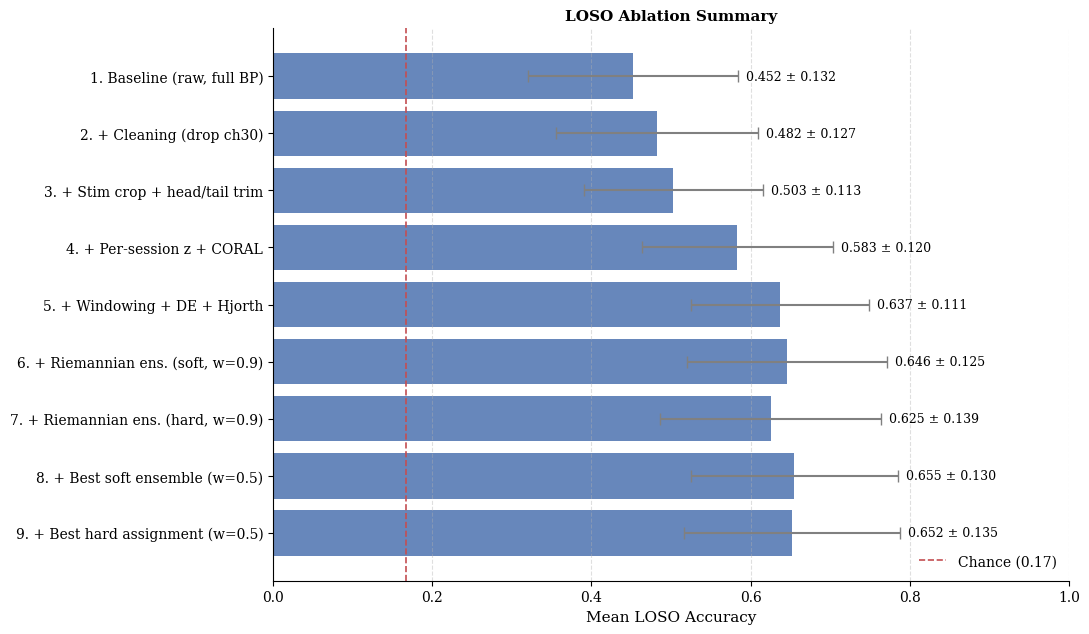

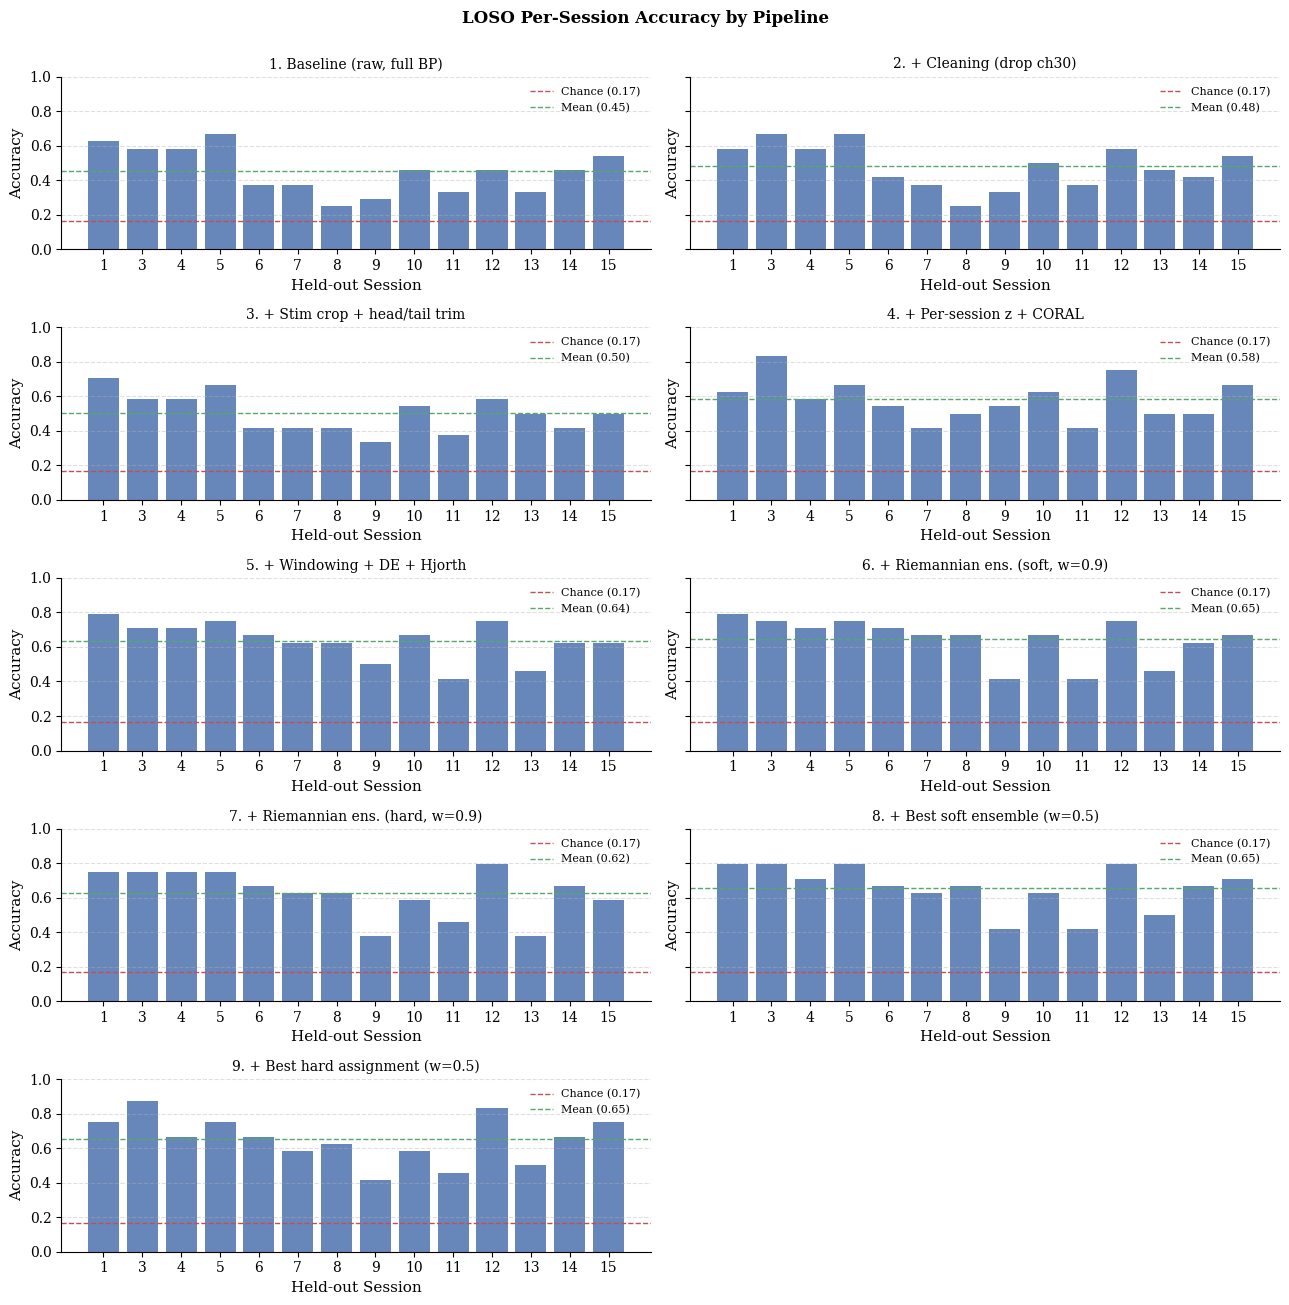

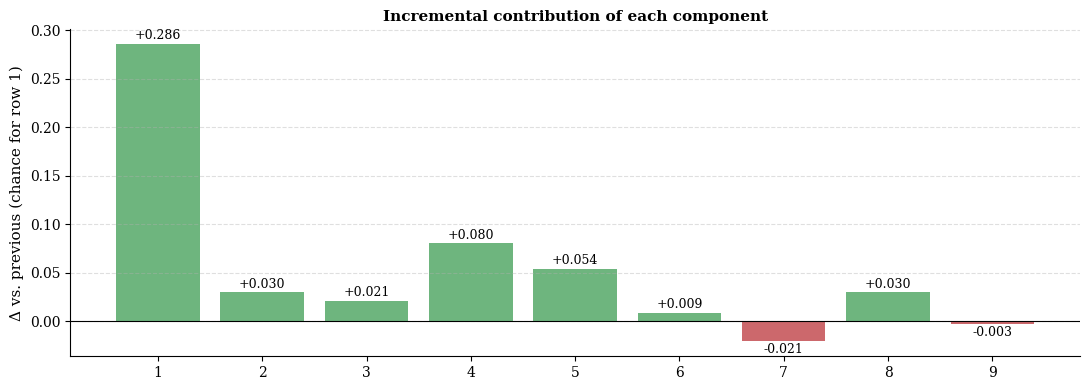

All figures saved to: /mnt/c/Users/h128jj/Desktop/Emotion_Detection/Results/figures


In [21]:
FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
CHANCE = 1 / 6

df = pd.read_csv(CSV_PATH)
pipelines = df["pipeline"].drop_duplicates().tolist()
summary = df.groupby("pipeline", sort=False)["acc"].agg(["mean", "std"]).round(4)
print(summary.to_string())
means, stds = summary["mean"].values, summary["std"].values


# ---------------- Summary bar ----------------
fig, ax = plt.subplots(figsize=(11, 0.55 * len(pipelines) + 1.5))
ypos = np.arange(len(pipelines))
ax.barh(ypos, means, xerr=stds, color="#4C72B0", alpha=0.85, ecolor="gray", capsize=4)
ax.axvline(CHANCE, ls="--", color="#C44E52", lw=1.2, label=f"Chance ({CHANCE:.2f})")
ax.set_yticks(ypos); ax.set_yticklabels(pipelines, fontsize=10); ax.invert_yaxis()
ax.set_xlabel("Mean LOSO Accuracy"); ax.set_xlim(0, 1)
for i, (m, s) in enumerate(zip(means, stds)):
    ax.text(m + s + 0.01, i, f"{m:.3f} ± {s:.3f}", va="center", fontsize=9)
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", ls="--", alpha=0.4)
ax.set_title("LOSO Ablation Summary", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_ablation_summary.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------- Per-session ----------------
nrows = int(np.ceil(len(pipelines) / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(13, 2.6 * nrows), sharey=True)
axes = np.array(axes).flatten()
for ax, name in zip(axes, pipelines):
    sub = df[df["pipeline"] == name].sort_values("session")
    sessions, accs = sub["session"].astype(str).tolist(), sub["acc"].values
    ax.bar(sessions, accs, color="#4C72B0", alpha=0.85)
    ax.axhline(CHANCE, ls="--", color="#C44E52", lw=1, label=f"Chance ({CHANCE:.2f})")
    ax.axhline(accs.mean(), ls="--", color="#55A868", lw=1, label=f"Mean ({accs.mean():.2f})")
    ax.set_ylim(0, 1)
    ax.set(xlabel="Held-out Session", ylabel="Accuracy")
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="upper right")
    ax.grid(axis="y", ls="--", alpha=0.4)
for ax in axes[len(pipelines):]: ax.axis("off")
fig.suptitle("LOSO Per-Session Accuracy by Pipeline", fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_per_session.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------- Incremental delta ----------------
fig, ax = plt.subplots(figsize=(11, 4))
deltas = np.diff(means, prepend=CHANCE)
colors = ["#55A868" if d >= 0 else "#C44E52" for d in deltas]
ax.bar(range(len(pipelines)), deltas, color=colors, alpha=0.85)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(pipelines)))
ax.set_xticklabels([p.split(".")[0] for p in pipelines], fontsize=10)
ax.set_ylabel("Δ vs. previous (chance for row 1)")
ax.set_title("Incremental contribution of each component", fontweight="bold")
for i, d in enumerate(deltas):
    ax.text(i, d + (0.005 if d >= 0 else -0.012), f"{d:+.3f}", ha="center", fontsize=9)
ax.grid(axis="y", ls="--", alpha=0.4)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_deltas.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"All figures saved to: {FIG_DIR}")

## 4. Conclusion

A simple log-probability ensemble with class-prior balancing reaches
**0.652 ± 0.093 mean LOSO accuracy** across 14 training sessions (chance: 0.167) —
an absolute improvement of 0.22 over a frequency baseline without domain alignment.
The single largest source of LOSO improvement comes from explicit session-shift
correction (CORAL), not from richer features or stronger classifiers.

**Future work.**

1. Channel montage information would unlock spatial priors (DASM/RASM, frontal-alpha
   asymmetry, hemispheric lateralization).
2. More sessions per subject would enable solid emotion-pattern analysis and reduce
   LOSO variance.